<a href="https://colab.research.google.com/github/rickycarrillo3/Learning_ML/blob/main/Demos/XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost from Scratch: Boosting Trees One Mistake at a Time

Welcome back! In the Decision_Trees demo we grew a single tree by repeatedly picking the best split. A single tree is easy to read, but it is often not very accurate. Today we ask: what if, instead of one big tree, we used many tiny ones that each correct the previous ones' errors?

Let's start with a dataset small enough to do by hand. We have six points with one feature:

| x | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| y | 3 | 4 | 2 | 9 | 11 | 10 |

The simplest possible prediction is the mean of y, which is 6.5 for every point. That is quite bad. We call the gap between the true value and our prediction the **residual** (y minus prediction), so our residuals are -3.5, -2.5, -4.5, 2.5, 4.5, 3.5.

But look at the pattern. The residuals are negative on the left (x = 1, 2, 3) and positive on the right (x = 4, 5, 6). A tiny tree with a single split between x = 3 and x = 4, called a **stump**, could capture that.

So here is the question we will answer: if we add half of that stump's output to our initial prediction (the mean), what are our new residuals? And what should the next tiny tree look at? Let's go through it in three small steps.

**Step 1: What does the stump output?** The stump is trained to predict the residuals, not y. Each side of the split gets one number, the average residual of the points on that side.

- Left side (residuals -3.5, -2.5, -4.5): the average is -3.5.
- Right side (residuals 2.5, 4.5, 3.5): the average is +3.5.

So the stump says: "on the left, we are too high by about 3.5, so subtract 3.5. On the right, we are too low by about 3.5, so add 3.5."

**Step 2: Add half of that output to our prediction.** We do not take the full step. We take half of it (this fraction is called the learning rate, usually denoted by $\alpha$, here 0.5). Taking small steps keeps any single tiny tree from having too much influence.

- Left: 6.5 + 0.5 x (-3.5) = 4.75
- Right: 6.5 + 0.5 x (+3.5) = 8.25

**Step 3: Recompute the residuals.** We compare the true y to the new predictions:

| x | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| y | 3 | 4 | 2 | 9 | 11 | 10 |
| new prediction | 4.75 | 4.75 | 4.75 | 8.25 | 8.25 | 8.25 |
| new residual | -1.75 | -0.75 | -2.75 | 0.75 | 2.75 | 1.75 |

Notice two things. First, every residual moved toward zero by 1.75, so each is exactly half the size it was before (for example, -3.5 became -1.75). We are closer, but we are not done, since we only took half a step. Second, the leftover mistakes are not all the same. On the left, x = 3 is still off by -2.75 while x = 2 is off by only -0.75. That kind of difference is what later trees can pick up.

**So what should the next tiny tree look at?** The new residuals, and nothing else. It does not look at the original y at all. It is trained to predict "what is the ensemble/combination of trees still getting wrong?", and whatever it outputs gets added (again, scaled by the learning rate) on top of what we have. Repeat this, and the prediction is simply the starting mean plus a sum of small corrections. Try the second round by hand before reading on: does the best cut land in the same place, or somewhere new?

Working this out raises a bigger question: why fit trees to residuals at all? It turns out the residual is secretly a very natural thing to chase: it is the direction in which the squared error shrinks fastest. We will make that precise later, and it lets us swap in other loss functions. That idea is the starting point of XGBoost.

**What we'll cover today:**

- Boosting the six points by hand, round by round
- Seeing residuals as gradients, and meeting the hessian (the second derivative)
- The XGBoost objective and its leaf-weight formula
- Implementing a small boosting loop from scratch in NumPy
- Applying it to a noisy 1D curve and watching it improve with each round

## Mathematical foundations

Let's turn our hand calculation into math. We will keep using the same six points:

| x | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| y | 3 | 4 | 2 | 9 | 11 | 10 |

### 1. The model is a sum of small corrections

In the intro, our prediction was the mean plus a scaled stump output. After $t$ rounds we simply keep stacking. Let $\hat y_i^{(t)}$ be the prediction for point $i$ after round $t$, $f_t$ the tiny tree built in round $t$, and $\alpha$ the learning rate:

$$\hat y_i^{(t)} = \hat y_i^{(t-1)} + \alpha\, f_t(x_i), \qquad \hat y_i^{(0)} = \bar y \qquad \text{(eq. 1)}$$

Unrolled, this is $\hat y_i^{(t)} = \bar y + \alpha f_1(x_i) + \alpha f_2(x_i) + \dots + \alpha f_t(x_i)$. On our toy data, $\bar y = 6.5$, $f_1$ outputs $-3.5$ on the left and $+3.5$ on the right, and with $\alpha = 0.5$ we get $4.75$ and $8.25$, just as before.

Why start at the mean? It is the best single constant under squared error. If we predict a constant $c$ everywhere, the derivative of $\tfrac12\sum_i (y_i - c)^2$ is $\sum_i (c - y_i)$. Setting it to zero gives $c = \bar y$.

What exactly is a tree here? It sends each point $x$ to one of $T$ leaves, and each leaf $j$ outputs a single number $w_j$, its **leaf weight**. Writing $q(x)$ for the leaf that $x$ lands in, we have $f(x) = w_{q(x)}$. Building a tree therefore means choosing two things:

- the splits, which decide $q$;
- the leaf weights $w_j$.

We will derive a formula for each.

### 2. Residuals are (negative) gradients

We measure mistakes with the squared error. The $\tfrac12$ is there only to make the derivative tidy:

$$\ell(y, \hat y) = \tfrac12 (y - \hat y)^2 \qquad \text{(eq. 2)}$$

Now ask the question from the intro. If we could nudge the prediction $\hat y_i$, which direction lowers the loss fastest? Take the derivative with respect to the prediction (not the input!):

$$g_i = \frac{\partial \ell(y_i, \hat y_i)}{\partial \hat y_i} = \hat y_i - y_i = -r_i \qquad \text{(eq. 3)}$$

$$h_i = \frac{\partial^2 \ell(y_i, \hat y_i)}{\partial \hat y_i^2} = 1 \qquad \text{(eq. 4)}$$

Here $g_i$ is the **gradient** and $h_i$ is the **hessian** (the second derivative). The residual $r_i = y_i - \hat y_i$ is exactly the negative gradient. So fitting a tree to residuals is gradient descent. Instead of nudging model weights, we nudge the predictions themselves.

For our toy data in round 1 ($\hat y_i = 6.5$ for all $i$):

| x | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $g_i$ | 3.5 | 2.5 | 4.5 | -2.5 | -4.5 | -3.5 |
| $h_i$ | 1 | 1 | 1 | 1 | 1 | 1 |

Why use a tree instead of nudging each point separately? Moving each training prediction on its own would just memorize the six points, and it would tell us nothing about a new $x$. The tree groups nearby points and gives them a shared nudge, so a new $x = 3.7$ also knows which way to move.

And why bother with $h_i$ when it is just 1? Because that is only true for squared error. For binary classification with the log loss and $p_i = \sigma(\hat y_i)$, we would get $g_i = p_i - y_i$ and $h_i = p_i(1 - p_i)$. XGBoost writes everything in terms of $g_i$ and $h_i$. Swapping the loss then means only changing eq. 3 and eq. 4; the rest of the algorithm stays the same.

### 3. A second-order approximation of the loss

Suppose the new tree adds $w$ to point $i$'s prediction. Its new loss is $\ell(y_i, \hat y_i + w)$. A Taylor expansion around the current prediction gives

$$\ell(y_i, \hat y_i + w) \approx \ell(y_i, \hat y_i) + g_i\, w + \tfrac12 h_i\, w^2 \qquad \text{(eq. 5)}$$

For squared error this is not even an approximation, it is exact. Check it on $x = 1$ with $y = 3$ and $\hat y = 6.5$:

$$\tfrac12(6.5 + w - 3)^2 = 6.125 + 3.5\,w + \tfrac12 w^2$$

This matches $g_1 = 3.5$ and $h_1 = 1$.

### 4. The XGBoost objective

A plain boosting loop would just minimize the loss. XGBoost also charges a price for complicated trees:

$$\Omega(f) = \gamma\, T + \tfrac12 \lambda \sum_{j=1}^{T} w_j^2 \qquad \text{(eq. 6)}$$

- $\gamma$ is a fixed cost for every leaf. Splitting must earn at least this much.
- $\lambda$ penalizes large leaf weights and pulls them toward zero, much like ridge regression.

The objective for round $t$ is the eq. 5 approximation summed over all points, plus the penalty. We drop $\ell(y_i, \hat y_i)$ because it does not depend on the new tree:

$$\mathcal{L}^{(t)} \approx \sum_{i=1}^{n} \Big[ g_i\, f_t(x_i) + \tfrac12 h_i\, f_t(x_i)^2 \Big] + \gamma T + \tfrac12 \lambda \sum_{j=1}^{T} w_j^2$$

Every point in leaf $j$ receives the same output $w_j$, so we can group the sum by leaf. Let $I_j$ be the set of points in leaf $j$ and define

$$G_j = \sum_{i \in I_j} g_i, \qquad H_j = \sum_{i \in I_j} h_i \qquad \text{(eq. 7)}$$

Then the objective becomes

$$\mathcal{L}^{(t)} \approx \sum_{j=1}^{T} \Big[ G_j\, w_j + \tfrac12 (H_j + \lambda)\, w_j^2 \Big] + \gamma T \qquad \text{(eq. 8)}$$

Each leaf is now its own little parabola in $w_j$, independent of the others. Note that $\alpha$ does not appear here. XGBoost finds the best tree first, then shrinks its output by $\alpha$ in eq. 1.

### 5. The best leaf weight

Minimizing a parabola is easy. Set the derivative $G_j + (H_j + \lambda) w_j$ to zero:

$$w_j^* = -\frac{G_j}{H_j + \lambda} \qquad \text{(eq. 9)}$$

This is a Newton step (gradient divided by curvature). Let's see what it means for squared error. There $H_j = n_j$, the number of points in the leaf, and $G_j = -\sum_{i \in I_j} r_i$, so

$$w_j^* = \frac{\sum_{i \in I_j} r_i}{n_j + \lambda}$$

With $\lambda = 0$, this is the average residual in the leaf, which is exactly what we computed by hand. On the left side, $G = 3.5 + 2.5 + 4.5 = 10.5$ and $H = 3$, so $w^* = -3.5$.

With $\lambda = 1$, we get $w^* = -10.5 / 4 = -2.625$ instead. A nice way to read $\lambda$: it acts like an extra phantom point in every leaf whose residual is 0, dragging the average toward zero. Small leaves are affected the most.

### 6. Scoring a split: the gain

We now know the best weights for a given tree shape. But which shape should we pick? Plug $w_j^*$ back into eq. 8. Each leaf contributes $-\tfrac{G_j^2}{H_j+\lambda} + \tfrac12 \tfrac{G_j^2}{H_j+\lambda} = -\tfrac12 \tfrac{G_j^2}{H_j+\lambda}$, so

$$\mathcal{L}^{*} = -\frac12 \sum_{j=1}^{T} \frac{G_j^2}{H_j + \lambda} + \gamma T \qquad \text{(eq. 10)}$$

Lower is better. Now consider splitting one leaf into a left child $L$ and a right child $R$.

- Before the split, that region contributes one term, $-\tfrac12 \tfrac{(G_L+G_R)^2}{H_L+H_R+\lambda} + \gamma$.
- After the split, it contributes two terms plus an extra $\gamma$.

The improvement is the **gain**:

$$\text{Gain} = \frac12 \left[ \frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda} \right] - \gamma \qquad \text{(eq. 11)}$$

Tree building is the same greedy search as in the Decision_Trees demo, just with a different score:

- Try every threshold, compute eq. 11, and keep the best.
- Only split if the best gain is positive.

### 7. Round 1 by hand ($\lambda = 0$, $\gamma = 0$)

The gradients sum to zero, so the parent has $G = 0$ and $H = 6$, and the third term in eq. 11 vanishes. Here is every possible cut:

| cut between | $G_L$ | $H_L$ | $G_R$ | $H_R$ | Gain |
|---|---|---|---|---|---|
| x = 1 and 2 | 3.5 | 1 | -3.5 | 5 | 7.35 |
| x = 2 and 3 | 6.0 | 2 | -6.0 | 4 | 13.5 |
| x = 3 and 4 | 10.5 | 3 | -10.5 | 3 | **36.75** |
| x = 4 and 5 | 8.0 | 4 | -8.0 | 2 | 24.0 |
| x = 5 and 6 | 3.5 | 5 | -3.5 | 1 | 7.35 |

The winner is the cut between 3 and 4, the one we eyeballed. Eq. 9 then gives leaf weights $-3.5$ and $+3.5$.

Sanity check: the gain should equal the actual drop in loss. Before the split, the loss is $\tfrac12 \sum r_i^2 = \tfrac12 \cdot 77.5 = 38.75$. If each side were fully corrected by its average residual, only $\tfrac12 \cdot 4 = 2$ would be left. And $38.75 - 2 = 36.75$. Sweet!

The regularizers change the picture:

- With $\lambda = 1$, the best gain shrinks to $\tfrac12 \big[\tfrac{10.5^2}{4} + \tfrac{10.5^2}{4}\big] = 27.56$.
- With $\gamma = 40$, even the best cut gives $36.75 - 40 < 0$. The tree refuses to split and stays a single leaf.

### 8. Round 2 by hand

After round 1 (with $\alpha = 0.5$), the residuals are $-1.75, -0.75, -2.75, 0.75, 2.75, 1.75$, so the gradients are their negatives. Notice that each side's average residual has halved, from $\mp 3.5$ to $\mp 1.75$. Each individual residual has not halved, though: every point moved by the same 1.75, so the differences between points on the same side are untouched.

| cut between | $G_L$ | $H_L$ | $G_R$ | $H_R$ | Gain |
|---|---|---|---|---|---|
| x = 1 and 2 | 1.75 | 1 | -1.75 | 5 | 1.84 |
| x = 2 and 3 | 2.5 | 2 | -2.5 | 4 | 2.34 |
| x = 3 and 4 | 5.25 | 3 | -5.25 | 3 | **9.19** |
| x = 4 and 5 | 4.5 | 4 | -4.5 | 2 | 7.59 |
| x = 5 and 6 | 1.75 | 5 | -1.75 | 1 | 1.84 |

So the answer to the question from the intro: in round 2, the cut lands in the same place again. The leaf weights are $\mp 1.75$, and the predictions become $3.875$ on the left and $9.125$ on the right.

But look at the margin. In round 1 the winner beat the runner-up 36.75 to 24. Now it is only 9.19 to 7.59. The error that the 3/4 cut can fix keeps shrinking with every round. Meanwhile, the within-side mistakes (for example, $x = 5$ is still too low) stay the same size. Try round 3 yourself; we will check the answer in code.

### 9. The full recipe

Putting it all together, this is exactly what our NumPy code will do:

1. Start every prediction at $\bar y$ (eq. 1).
2. For each round $t = 1, \dots, M$:
   1. Compute $g_i$ and $h_i$ for every point (eq. 3, eq. 4).
   2. Grow a small tree greedily. At each node, sum $G$ and $H$ on each side of every candidate threshold (eq. 7) and score the threshold with eq. 11. Split on the best one if its gain is positive and we have not hit the maximum depth.
   3. Set each leaf's weight with eq. 9.
   4. Update all predictions with the learning rate (eq. 1).

The hyperparameters we will expose are the number of rounds $M$, the learning rate $\alpha$, the maximum tree depth, $\lambda$, and $\gamma$.

## Questions for you

Before (or while) reading the code, try these. Questions 1-3 are technical: pencil-and-paper work (mostly on our six points) that you can check by hand. Questions 4-5 are conceptual: they build intuition for the hyperparameters we will expose in the code ($\alpha$, $M$, $\lambda$, $\gamma$). Each answer is hidden below its question.

**Question 1.** In round 1, set $\lambda = 1$ and $\gamma = 0$, and keep the cut between $x = 3$ and $x = 4$. What are the two leaf weights (eq. 9)? With $\alpha = 0.5$, what are the new predictions on each side, and how do they compare to the $4.75$ and $8.25$ we got with $\lambda = 0$?

<details><summary>Show answer</summary>

Left leaf: $G_L = 10.5$, $H_L = 3$, so $w_L^* = -10.5 / (3 + 1) = -2.625$. Right leaf: $G_R = -10.5$, $H_R = 3$, so $w_R^* = +2.625$.

With $\alpha = 0.5$, the left prediction is $6.5 + 0.5 \times (-2.625) = 5.1875$, and the right prediction is $6.5 + 0.5 \times 2.625 = 7.8125$.

Both predictions are closer to the mean than the $4.75$ and $8.25$ from before. That is the effect of $\lambda$: it shrinks leaf weights toward zero, so the first round takes a more cautious step.

</details>

**Question 2.** Do round 3 by hand with $\lambda = 0$, $\gamma = 0$, $\alpha = 0.5$. After round 2 the predictions are $3.875$ for $x = 1, 2, 3$ and $9.125$ for $x = 4, 5, 6$. Compute the gradients, score every cut with eq. 11, and say where the best cut lands. Is it still between $x = 3$ and $x = 4$?

<details><summary>Show answer</summary>

The residuals are $-0.875, 0.125, -1.875, -0.125, 1.875, 0.875$, so the gradients are their negatives: $0.875, -0.125, 1.875, 0.125, -1.875, -0.875$. They sum to zero, so the third term in eq. 11 vanishes again.

| cut between | $G_L$ | $H_L$ | Gain |
|---|---|---|---|
| x = 1 and 2 | 0.875 | 1 | 0.46 |
| x = 2 and 3 | 0.75 | 2 | 0.21 |
| x = 3 and 4 | 2.625 | 3 | 2.30 |
| x = 4 and 5 | 2.75 | 4 | **2.84** |
| x = 5 and 6 | 0.875 | 5 | 0.46 |

The best cut moves to between $x = 4$ and $x = 5$. By now the 3/4 cut has already fixed most of what it can, and the biggest remaining mistakes are $x = 5$ and $x = 3$ (both still too low).

The leaf weights are $-2.75/4 = -0.6875$ on the left and $+2.75/2 = +1.375$ on the right. With $\alpha = 0.5$, the new predictions are $3.53125$ for $x = 1, 2, 3$, $8.78125$ for $x = 4$, and $9.8125$ for $x = 5, 6$. The residual at $x = 5$ drops from $1.875$ to $1.1875$.

Different rounds can cut in different places. That is how a sum of tiny trees ends up more flexible than any single stump.

</details>

**Question 3.** Eq. 3 and eq. 4 gave $g_i$ and $h_i$ for squared error. For binary log loss, $g_i = p_i - y_i$ and $h_i = p_i(1 - p_i)$ with $p_i = \sigma(\hat y_i)$. Suppose a leaf holds a single point with $y = 1$, the current prediction is $\hat y = 0$, and $\lambda = 0$. What are $g$, $h$, and the leaf weight from eq. 9? Which part of the XGBoost algorithm would have to change to use this loss?

<details><summary>Show answer</summary>

With $\hat y = 0$ we have $p = \sigma(0) = 0.5$. So $g = 0.5 - 1 = -0.5$ and $h = 0.5 \times 0.5 = 0.25$.

The leaf weight is $w^* = -g/h = 0.5 / 0.25 = 2$. The sign is positive, so the raw score $\hat y$ is pushed up toward class 1, which is what we want.

Only the computation of $g_i$ and $h_i$ would change. The gain (eq. 11), the leaf weights (eq. 9), and the update rule (eq. 1) are written purely in terms of $G$ and $H$, so they stay the same.

</details>

**Question 4 (learning rate and number of rounds).** Suppose, for argument's sake, that every round used the same cut between $x = 3$ and $x = 4$, with $\lambda = 0$. Then each leaf weight is the average residual on that side, and eq. 1 adds $\alpha$ times it. So each round multiplies the average residual on a side by $(1 - \alpha)$. On the left side it starts at $3.5$ in magnitude. How many rounds until it is below $0.1$ for $\alpha = 0.5$? For $\alpha = 0.1$? And given that $\alpha = 1$ would zero out the average residual in a single round, why would anyone choose a small $\alpha$ and pay for many more rounds?

<details><summary>Show answer</summary>

After $t$ rounds the average residual has magnitude $3.5\,(1 - \alpha)^t$.

- $\alpha = 0.5$: $3.5 \times 0.5^5 \approx 0.109$ is still too big, and $3.5 \times 0.5^6 \approx 0.055$ is below $0.1$. So we need **6 rounds**. (You can check the early steps against our hand calculations: $3.5 \to 1.75 \to 0.875$.)
- $\alpha = 0.1$: we need $0.9^t < 0.1/3.5$, which gives $t > 33.7$. So we need **34 rounds**.

Smaller $\alpha$ means more rounds (and more compute) for the same progress, so $\alpha$ and $M$ trade off against each other.

So why not $\alpha = 1$? Because each leaf weight is an average over only a few points (three here), and with real data those points are noisy. With $\alpha = 1$, round 1 gives predictions $3$ and $10$ and leaves residuals $0, 1, -1, -1, 1, 0$. The model has fully committed to whatever the first tree believed, noise included. With a small $\alpha$, each tree contributes only a little, later trees (which may cut elsewhere, like the 4/5 cut in Question 2) can correct earlier mistakes, and the many small, slightly different corrections average out the noise. The usual recipe is a small $\alpha$ with enough rounds to compensate. Too few rounds with a small $\alpha$ underfits, and running far too many rounds can still overfit.

</details>

**Question 5 ($\lambda$, $\gamma$ and tree size as brakes).** Use stumps (one split per tree) with $\lambda = 0$ and $\alpha = 0.5$, and set $\gamma = 10$. Using the best gains we computed ($36.75$ in round 1, $9.19$ in round 2), what does the model do in round 1, in round 2, and in every round after that? Then compare: for squared error, $\lambda = 1$ shrinks a leaf weight by the factor $n_j/(n_j + \lambda)$, so what happens to a leaf with 1 point, 3 points, and 99 points? In one sentence each, what does $\lambda$ control, what does $\gamma$ control, and what does the maximum depth control?

<details><summary>Show answer</summary>

**$\gamma = 10$.**

- Round 1: the best gain after the penalty is $36.75 - 10 = 26.75 > 0$, so the tree splits at 3/4 and the predictions become $4.75$ and $8.25$.
- Round 2: the best gain is $9.19 - 10 < 0$, so the tree refuses to split and stays a single leaf. After round 1 the gradients sum to zero, so $G = 0$ and that leaf has weight $w^* = 0$. The predictions do not change.
- Round 3 and later: the gradients are the same as in round 2, so the same thing happens again. Boosting stalls after one useful round.

So $\gamma$ is a minimum-improvement bar. Because the gains shrink every round, a large enough $\gamma$ acts like built-in early stopping. With $\gamma = 40$ even round 1 would be rejected, and the model would never leave the mean.

**$\lambda$.** The shrink factor is $n_j/(n_j + \lambda)$:

- 1 point: $1/2 = 0.5$, so the weight is halved.
- 3 points: $3/4 = 0.75$, which matches the $-2.625$ vs $-3.5$ from the math section.
- 99 points: $99/100 = 0.99$, so almost no change.

Leaves that rest on very little evidence are the likeliest to chase noise, and they are exactly the ones $\lambda$ pulls hardest toward zero. (It also lowers the gain of splits that create tiny leaves, since $H + \lambda$ sits in the denominators of eq. 11. For example, the round 1 best gain drops from $36.75$ to $27.56$.)

**Summary.**

- $\lambda$ controls how big each leaf's output is allowed to be (a soft brake on every leaf, strongest on small ones).
- $\gamma$ controls whether a split is worth making at all (a hard bar on gain).
- The maximum depth controls how many splits a single tree may stack, i.e. how complex a pattern one tree can express.

All three limit how much any one tree can overfit, and none of them replaces $\alpha$, which limits how much each tree is trusted.

</details>

## Implementation from scratch

Time to turn the recipe from section 9 into code. We will build it from small pieces:

1. the gradient and hessian of the squared error (eq. 3, eq. 4),
2. the leaf weight (eq. 9) and the split gain (eq. 11),
3. a greedy search for the best split,
4. a recursive tree builder,
5. the boosting loop (eq. 1).

After each piece, we check it against the numbers we worked out by hand on our six points. Let's start with the imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random

# Fix the random seeds so every run of the notebook gives the same results
np.random.seed(0)
random.seed(0)

First, our toy dataset. We store the inputs as a 2D array of shape `(n_points, n_features)`, even though there is only one feature here. The tree code will then work unchanged for data with several features.

In [2]:
# The six points from the intro
x_toy = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y_toy = np.array([3, 4, 2, 9, 11, 10], dtype=float)

# Reshape to (n_points, n_features) = (6, 1): one row per point, one column per feature
X_toy = x_toy.reshape(-1, 1)

print('X shape:', X_toy.shape)
print('mean of y:', np.mean(y_toy))  # our starting prediction (eq. 1), should be 6.5

X shape: (6, 1)
mean of y: 6.5


### Step 1: gradients and hessians

For the squared error (eq. 2), the gradient is $g_i = \hat y_i - y_i$ (eq. 3) and the hessian is $h_i = 1$ (eq. 4). This is the only loss-specific function in the whole notebook. To swap in another loss (like the log loss from Question 3), we would only rewrite this one function.

In [3]:
def squared_error_grad_hess(y, y_pred):
    """
    Gradient and hessian of the squared error 1/2 (y - y_pred)^2 (eq. 2)
    with respect to the prediction y_pred, for every point at once.
    """
    # Gradient: g_i = y_pred_i - y_i, i.e. the negative residual (eq. 3)
    g = y_pred - y
    # Hessian: h_i = 1 for every point (eq. 4)
    h = np.ones_like(y)
    # In plain Python this would be:
    # g = [y_pred[i] - y[i] for i in range(len(y))]
    # h = [1.0 for i in range(len(y))]
    return g, h


# Check against the round 1 table in section 2: every prediction starts at the mean
y_pred_start = np.full(len(y_toy), np.mean(y_toy))
g_check, h_check = squared_error_grad_hess(y_toy, y_pred_start)
print('g:', g_check)  # expected: 3.5, 2.5, 4.5, -2.5, -4.5, -3.5
print('h:', h_check)  # expected: all ones

g: [ 3.5  2.5  4.5 -2.5 -4.5 -3.5]
h: [1. 1. 1. 1. 1. 1.]


### Step 2: leaf weight and split gain

These two formulas are the heart of XGBoost. Both only need the sums $G$ and $H$ of a group of points (eq. 7):

- the best leaf weight is $w^* = -G / (H + \lambda)$ (eq. 9),
- the gain of a split compares the score $G^2/(H+\lambda)$ of the two children with the score of the parent, minus $\gamma$ (eq. 11).

In [4]:
def leaf_weight(G, H, reg_lambda):
    """Best output for a leaf with gradient sum G and hessian sum H (eq. 9)."""
    # Newton step: minus gradient divided by (curvature + L2 penalty)
    return -G / (H + reg_lambda)


def leaf_score(G, H, reg_lambda):
    """How much a leaf lowers the objective, up to the factor -1/2 (eq. 10)."""
    return G ** 2 / (H + reg_lambda)


def split_gain(G_L, H_L, G_R, H_R, reg_lambda, gamma):
    """Improvement in the objective from splitting one leaf into L and R (eq. 11)."""
    # Score of the two children if we split
    children = leaf_score(G_L, H_L, reg_lambda) + leaf_score(G_R, H_R, reg_lambda)
    # Score of the single parent leaf if we do not split
    parent = leaf_score(G_L + G_R, H_L + H_R, reg_lambda)
    # Half the difference, minus the price gamma for the extra leaf
    return 0.5 * (children - parent) - gamma


# Quick check from section 5: the left side in round 1 has G = 10.5 and H = 3
print('w* with lambda = 0:', leaf_weight(10.5, 3, 0.0))  # expected -3.5
print('w* with lambda = 1:', leaf_weight(10.5, 3, 1.0))  # expected -2.625

w* with lambda = 0: -3.5
w* with lambda = 1: -2.625


Let's reproduce the round 1 table from section 7 by scoring every possible cut. Our toy $x$ values are already sorted, so the left child of the $k$-th cut is simply the first $k+1$ points.

Feel free to change $\lambda$ and $\gamma$ here. With $\lambda = 1$, the best gain should drop to $27.56$, and with $\gamma = 40$, every gain should turn negative.

In [5]:
# ==== Hyperparameters (feel free to change!) ====
reg_lambda = 0.0   # @param {type:"number"} L2 penalty on leaf weights (eq. 6), try 0-10
gamma = 0.0        # @param {type:"number"} price per extra leaf (eq. 6), try 0-50
# ================================================

# Round 1: every prediction is the mean (eq. 1), so compute g and h there (eq. 3, eq. 4)
y_pred_round1 = np.full(len(y_toy), np.mean(y_toy))
g_r1, h_r1 = squared_error_grad_hess(y_toy, y_pred_round1)

# Totals for the parent node (eq. 7)
G_total, H_total = g_r1.sum(), h_r1.sum()

print(f"{'cut between':>14} | {'G_L':>6} | {'H_L':>4} | {'G_R':>6} | {'H_R':>4} | {'Gain':>7}")
for k in range(len(x_toy) - 1):
    # Left child = the first k+1 points, right child = the rest (eq. 7)
    G_L, H_L = g_r1[:k + 1].sum(), h_r1[:k + 1].sum()
    G_R, H_R = G_total - G_L, H_total - H_L
    # Score this cut (eq. 11)
    gain = split_gain(G_L, H_L, G_R, H_R, reg_lambda, gamma)
    cut_name = f'x = {x_toy[k]:.0f} and {x_toy[k + 1]:.0f}'
    print(f'{cut_name:>14} | {G_L:6.2f} | {H_L:4.0f} | {G_R:6.2f} | {H_R:4.0f} | {gain:7.2f}')

   cut between |    G_L |  H_L |    G_R |  H_R |    Gain
   x = 1 and 2 |   3.50 |    1 |  -3.50 |    5 |    7.35
   x = 2 and 3 |   6.00 |    2 |  -6.00 |    4 |   13.50
   x = 3 and 4 |  10.50 |    3 | -10.50 |    3 |   36.75
   x = 4 and 5 |   8.00 |    4 |  -8.00 |    2 |   24.00
   x = 5 and 6 |   3.50 |    5 |  -3.50 |    1 |    7.35


Sweet, the cut between 3 and 4 wins with a gain of $36.75$, just like in section 7.

### Step 3: finding the best split

Now we automate that table for any data. For each feature, we:

1. sort the points by that feature,
2. walk through them from left to right, moving one point at a time from the right child to the left child,
3. keep running sums $G_L$ and $H_L$ (and get $G_R$, $H_R$ by subtracting from the total),
4. score each cut with eq. 11.

The threshold is placed halfway between two neighbouring values. We cannot cut between two equal values, so we skip those. The running sums are the trick that makes this fast: we never re-add a whole group of points from scratch.

In [6]:
def find_best_split(X, g, h, reg_lambda, gamma):
    """
    Greedy search over every feature and every threshold.
    Returns (best_gain, best_feature, best_threshold).
    best_feature is None if no cut is possible (e.g. all x values equal).
    """
    n_points, n_features = X.shape
    # Totals for the current node (eq. 7)
    G_total, H_total = g.sum(), h.sum()

    best_gain, best_feature, best_threshold = -np.inf, None, None

    for j in range(n_features):
        # Sort the points by feature j so every cut is 'first k points vs the rest'
        order = np.argsort(X[:, j])
        x_sorted, g_sorted, h_sorted = X[order, j], g[order], h[order]

        # Running sums for the left child; it starts empty
        G_L, H_L = 0.0, 0.0
        for k in range(n_points - 1):
            # Move point k from the right child to the left child (eq. 7)
            G_L += g_sorted[k]
            H_L += h_sorted[k]
            # The right child is whatever is left over
            G_R, H_R = G_total - G_L, H_total - H_L

            # We cannot put a threshold between two identical values
            if x_sorted[k] == x_sorted[k + 1]:
                continue

            # Score this cut (eq. 11)
            gain = split_gain(G_L, H_L, G_R, H_R, reg_lambda, gamma)
            # Keep it if it beats everything so far
            if gain > best_gain:
                best_gain = gain
                best_feature = j
                # Threshold halfway between the two neighbouring values
                best_threshold = (x_sorted[k] + x_sorted[k + 1]) / 2

    return best_gain, best_feature, best_threshold


# Check on round 1 of the toy data (lambda = 0, gamma = 0): expect gain 36.75 at x < 3.5
print(find_best_split(X_toy, g_r1, h_r1, reg_lambda=0.0, gamma=0.0))

(np.float64(36.75), 0, np.float64(3.5))


### Step 4: growing a tree

Now we grow a whole tree recursively, exactly as in the Decision_Trees demo, but with the XGBoost score. At each node:

- if we have not reached the maximum depth, look for the best split;
- if its gain is positive, split the points and grow both children;
- otherwise, make this node a leaf with weight $w^*$ (eq. 9).

We store the tree as nested dictionaries. With `max_depth = 1` we get a stump: the root may split once, and both children become leaves.

In [7]:
def build_tree(X, g, h, depth, max_depth, reg_lambda, gamma):
    """
    Recursively grow one XGBoost tree on the gradients g and hessians h.
    Returns a nested dict: either a leaf or a split node with 'left' and 'right'.
    """
    # Gradient and hessian sums of the points in this node (eq. 7)
    G, H = g.sum(), h.sum()

    # Only try to split if we are not too deep and have at least 2 points
    if depth < max_depth and len(g) >= 2:
        gain, feature, threshold = find_best_split(X, g, h, reg_lambda, gamma)
        # Split only if a cut exists and it improves the objective (gain > 0, eq. 11)
        if feature is not None and gain > 0:
            # Points with a smaller feature value go left, the rest go right
            goes_left = X[:, feature] < threshold
            goes_right = ~goes_left
            # Grow both children one level deeper
            left = build_tree(X[goes_left], g[goes_left], h[goes_left],
                              depth + 1, max_depth, reg_lambda, gamma)
            right = build_tree(X[goes_right], g[goes_right], h[goes_right],
                               depth + 1, max_depth, reg_lambda, gamma)
            return {'leaf': False, 'feature': feature, 'threshold': threshold,
                    'gain': gain, 'left': left, 'right': right}

    # Otherwise this node is a leaf with the best weight (eq. 9)
    return {'leaf': True, 'weight': leaf_weight(G, H, reg_lambda), 'n_points': len(g)}


def predict_tree(tree, x):
    """Send one point x down the tree and return its leaf weight, f(x) = w_q(x)."""
    node = tree
    # Follow the splits until we reach a leaf
    while not node['leaf']:
        node = node['left'] if x[node['feature']] < node['threshold'] else node['right']
    return node['weight']


def predict_tree_batch(tree, X):
    """Tree output for every row of X."""
    return np.array([predict_tree(tree, x) for x in X])


def print_tree(node, indent=''):
    """Print a tree as readable if/else rules."""
    if node['leaf']:
        print(f"{indent}leaf: w = {node['weight']:+.4f}  ({node['n_points']} points)")
    else:
        print(f"{indent}if x[{node['feature']}] < {node['threshold']:.3f}:   (gain = {node['gain']:.4f})")
        print_tree(node['left'], indent + '    ')
        print(f'{indent}else:')
        print_tree(node['right'], indent + '    ')

Let's grow the round 1 tree on our toy data. We expect a cut at $x < 3.5$ with gain $36.75$ and leaf weights $-3.5$ and $+3.5$. Try `max_depth = 2` too and see which extra cuts the tree picks inside each side.

In [8]:
# ==== Hyperparameters (feel free to change!) ====
max_depth = 1      # @param {type:"slider", min:1, max:3} 1 = stump; deeper = more splits per tree
reg_lambda = 0.0   # @param {type:"number"} L2 penalty on leaf weights (eq. 6), try 0-10
gamma = 0.0        # @param {type:"number"} price per extra leaf (eq. 6), try 0-50
# ================================================

# Grow one tree on the round 1 gradients and hessians (eq. 3, eq. 4)
tree_round1 = build_tree(X_toy, g_r1, h_r1, depth=0, max_depth=max_depth,
                         reg_lambda=reg_lambda, gamma=gamma)
print_tree(tree_round1)

# The tree's raw output for each of the six points (before the learning rate)
print('\nf_1(x):', predict_tree_batch(tree_round1, X_toy))

if x[0] < 3.500:   (gain = 36.7500)
    leaf: w = -3.5000  (3 points)
else:
    leaf: w = +3.5000  (3 points)

f_1(x): [-3.5 -3.5 -3.5  3.5  3.5  3.5]


### Step 5: the boosting loop

Now we put everything together in a small class. `fit` follows the recipe from section 9 line by line:

1. start every prediction at $\bar y$,
2. each round, compute $g$ and $h$, grow a tree, and add $\alpha$ times its output (eq. 1).

`predict` replays the same sum on new points. It also accepts `n_trees`, so we can ask what the model predicted after only the first few rounds. That will be handy for watching the model improve round by round.

The hyperparameter block at the top of the cell sets the default settings of the class. These defaults match our hand calculation. Any model can still override them when we create it, as the cells below do.

In [9]:
# ==== Hyperparameters (feel free to change!) ====
# Default settings of XGBoostRegressor; each can be overridden when creating a model
n_rounds = 3         # @param {type:"slider", min:1, max:200} number of trees M, more = closer fit but slower
learning_rate = 0.5  # @param {type:"number"} alpha in eq. 1, try 0.05-1
max_depth = 1        # @param {type:"slider", min:1, max:5} depth of each tree, 1 = stumps
reg_lambda = 0.0     # @param {type:"number"} L2 penalty on leaf weights (eq. 6), try 0-10
gamma = 0.0          # @param {type:"number"} price per extra leaf (eq. 6), try 0-50
# ================================================

class XGBoostRegressor:
    # Default argument values come from the hyperparameter block above
    def __init__(self, n_rounds=n_rounds, learning_rate=learning_rate,
                 max_depth=max_depth, reg_lambda=reg_lambda, gamma=gamma):
        self.n_rounds = n_rounds            # M: how many trees to add
        self.learning_rate = learning_rate  # alpha in eq. 1
        self.max_depth = max_depth          # maximum depth of each tree
        self.reg_lambda = reg_lambda        # lambda in eq. 6
        self.gamma = gamma                  # gamma in eq. 6
        self.base_prediction = None         # y-bar, the starting point of eq. 1
        self.trees = []                     # f_1, ..., f_M
        self.train_loss = []                # training MSE before round 1 and after each round

    def fit(self, X, y, verbose=False):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        # Start every prediction at the mean, the best constant under squared error (eq. 1)
        self.base_prediction = np.mean(y)
        y_pred = np.full(len(y), self.base_prediction)
        self.trees = []
        self.train_loss = [np.mean((y - y_pred) ** 2)]

        for t in range(1, self.n_rounds + 1):
            # Gradient and hessian at the current predictions (eq. 3, eq. 4)
            g, h = squared_error_grad_hess(y, y_pred)
            # Grow a tree greedily with the gain (eq. 11) and leaf weights (eq. 9)
            tree = build_tree(X, g, h, depth=0, max_depth=self.max_depth,
                              reg_lambda=self.reg_lambda, gamma=self.gamma)
            # Add a shrunken copy of the tree's output to the predictions (eq. 1)
            y_pred = y_pred + self.learning_rate * predict_tree_batch(tree, X)
            self.trees.append(tree)
            # Track how well we fit the training data
            self.train_loss.append(np.mean((y - y_pred) ** 2))

            if verbose:
                print(f'--- Round {t} --- training MSE: {self.train_loss[-1]:.4f}')
                print_tree(tree)
        return self

    def predict(self, X, n_trees=None):
        """Prediction = y-bar + alpha * (f_1(x) + ... + f_k(x)), using the first k trees (eq. 1)."""
        X = np.asarray(X, dtype=float)
        if n_trees is None:
            n_trees = len(self.trees)
        # Start from the mean ...
        y_pred = np.full(len(X), self.base_prediction)
        # ... and stack the small corrections one by one
        for tree in self.trees[:n_trees]:
            y_pred = y_pred + self.learning_rate * predict_tree_batch(tree, X)
        return y_pred

### Checking against our hand calculations

The moment of truth! With stumps, $\alpha = 0.5$, $\lambda = 0$ and $\gamma = 0$, the code should reproduce:

- round 1: cut at 3/4, predictions $4.75$ and $8.25$ (the intro),
- round 2: cut at 3/4 again, predictions $3.875$ and $9.125$ (section 8),
- round 3: cut moves to 4/5, predictions $3.53125$, $8.78125$, $9.8125$ (Question 2).

The settings below are the ones from the hand calculation. If you change them, the comparison will (rightly) say `False`.

In [10]:
# ==== Hyperparameters (keep these to match the hand calculation) ====
n_rounds = 3         # @param {type:"slider", min:1, max:10} number of trees M
learning_rate = 0.5  # @param {type:"number"} alpha in eq. 1, try 0.05-1
max_depth = 1        # @param {type:"slider", min:1, max:3} 1 = stumps
reg_lambda = 0.0     # @param {type:"number"} L2 penalty on leaf weights (eq. 6)
gamma = 0.0          # @param {type:"number"} price per extra leaf (eq. 6)
# =====================================================================

# Fit the boosted model on the six points, printing every tree
model_toy = XGBoostRegressor(n_rounds, learning_rate, max_depth, reg_lambda, gamma)
model_toy.fit(X_toy, y_toy, verbose=True)

# Predictions we computed by hand after rounds 1, 2 and 3
hand_predictions = {
    1: [4.75] * 3 + [8.25] * 3,
    2: [3.875] * 3 + [9.125] * 3,
    3: [3.53125] * 3 + [8.78125] + [9.8125] * 2,
}

print()
for k, expected in hand_predictions.items():
    # Use only the first k trees (eq. 1 after k rounds)
    code_pred = model_toy.predict(X_toy, n_trees=k)
    residuals = y_toy - code_pred
    print(f'After round {k}:')
    print('  predictions:', np.round(code_pred, 5))
    print('  residuals:  ', np.round(residuals, 5))
    print('  matches hand calculation:', np.allclose(code_pred, expected))

--- Round 1 --- training MSE: 3.7292
if x[0] < 3.500:   (gain = 36.7500)
    leaf: w = -3.5000  (3 points)
else:
    leaf: w = +3.5000  (3 points)
--- Round 2 --- training MSE: 1.4323
if x[0] < 3.500:   (gain = 9.1875)
    leaf: w = -1.7500  (3 points)
else:
    leaf: w = +1.7500  (3 points)
--- Round 3 --- training MSE: 0.7233
if x[0] < 4.500:   (gain = 2.8359)
    leaf: w = -0.6875  (4 points)
else:
    leaf: w = +1.3750  (2 points)

After round 1:
  predictions: [4.75 4.75 4.75 8.25 8.25 8.25]
  residuals:   [-1.75 -0.75 -2.75  0.75  2.75  1.75]
  matches hand calculation: True
After round 2:
  predictions: [3.875 3.875 3.875 9.125 9.125 9.125]
  residuals:   [-0.875  0.125 -1.875 -0.125  1.875  0.875]
  matches hand calculation: True
After round 3:
  predictions: [3.53125 3.53125 3.53125 8.78125 9.8125  9.8125 ]
  residuals:   [-0.53125  0.46875 -1.53125  0.21875  1.1875   0.1875 ]
  matches hand calculation: True


Nice! All three rounds match, including the moment in round 3 where the best cut jumps from 3/4 to 4/5. Notice also how the training MSE drops every round, but by less and less, just like the shrinking gains in section 8.

### Watching the regularizers at work

Finally, let's check the two "brakes" from Questions 1 and 5. The defaults below use $\gamma = 10$ (Question 5): round 1 should split, and every later round should refuse to split and produce a single leaf with weight $0$, so the predictions freeze at $4.75$ and $8.25$.

Then try `reg_lambda = 1.0` and `gamma = 0.0` (Question 1): after round 1 the predictions should be $5.1875$ and $7.8125$. Feel free to play with both.

In [11]:
# ==== Hyperparameters (feel free to change!) ====
n_rounds = 4         # @param {type:"slider", min:1, max:10} number of trees M
learning_rate = 0.5  # @param {type:"number"} alpha in eq. 1, try 0.05-1
max_depth = 1        # @param {type:"slider", min:1, max:3} 1 = stumps
reg_lambda = 0.0     # @param {type:"number"} L2 penalty on leaf weights (eq. 6), try 0-10
gamma = 10.0         # @param {type:"number"} price per extra leaf (eq. 6), try 0-50
# ================================================

# Fit a model with these brakes and print every tree it grows
model_reg = XGBoostRegressor(n_rounds, learning_rate, max_depth, reg_lambda, gamma)
model_reg.fit(X_toy, y_toy, verbose=True)

# Show how the predictions evolve round by round (eq. 1 with the first k trees)
print()
for k in range(1, n_rounds + 1):
    print(f'After round {k}: predictions = {np.round(model_reg.predict(X_toy, n_trees=k), 5)}')

--- Round 1 --- training MSE: 3.7292
if x[0] < 3.500:   (gain = 26.7500)
    leaf: w = -3.5000  (3 points)
else:
    leaf: w = +3.5000  (3 points)
--- Round 2 --- training MSE: 3.7292
leaf: w = -0.0000  (6 points)
--- Round 3 --- training MSE: 3.7292
leaf: w = -0.0000  (6 points)
--- Round 4 --- training MSE: 3.7292
leaf: w = -0.0000  (6 points)

After round 1: predictions = [4.75 4.75 4.75 8.25 8.25 8.25]
After round 2: predictions = [4.75 4.75 4.75 8.25 8.25 8.25]
After round 3: predictions = [4.75 4.75 4.75 8.25 8.25 8.25]
After round 4: predictions = [4.75 4.75 4.75 8.25 8.25 8.25]


With $\gamma = 10$, the tree printouts show the story from Question 5. Round 1 has gain $36.75 - 10 > 0$, so it splits. Round 2 would only gain $9.19 - 10 < 0$, so it stays a single leaf. Because the gradients sum to zero, that leaf's weight is $0$ (up to tiny floating-point noise), and boosting stalls.

We now have a working XGBoost regressor in about a hundred lines of NumPy. It is not magic: there is a mean, a derivative, a parabola, and a greedy search. Next, we will let it loose on a noisier and bigger dataset.

## Application: predicting diabetes progression

Our six points were perfect for checking every number by hand. Now let's see what boosting does on real, noisy data.

We use the diabetes dataset that ships with scikit-learn. It has 442 patients and 10 features measured at a first visit: age, sex, body mass index (`bmi`), average blood pressure (`bp`), and six blood serum measurements (`s1` to `s6`). The target measures how much the disease progressed one year later. The features are already standardized (centered and scaled), so there is no preprocessing to do.

We will put four models side by side on the same held-out test set:

- **(a) Mean only:** predict the training mean for everyone. This is eq. 1 with zero trees.
- **(b) Linear regression:** our old friend from the linear regression demo, now with 10 features at once.
- **(c) One deep tree:** a single greedy tree of depth 6, like in the Decision_Trees demo.
- **(d) Boosted shallow trees:** 150 trees of depth 2, each shrunk by $\alpha = 0.1$.

The questions for today: do many weak trees beat one strong-looking tree? And how do both compare with a plain hyperplane?

train: (353, 10)   test: (89, 10)
features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
target: min 25, max 346, mean 152.1, std 77.0


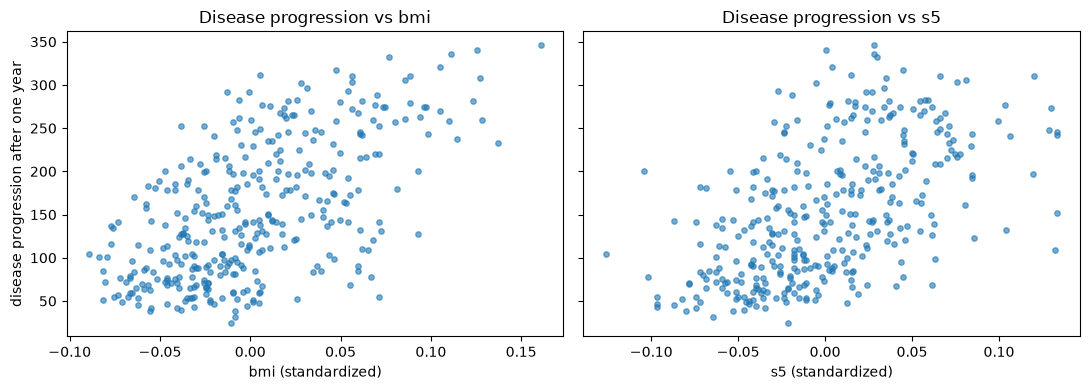

In [12]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# ==== Hyperparameters (feel free to change!) ====
test_fraction = 0.2   # @param {type:"number"} share of patients held out for testing, try 0.1-0.4
split_seed = 42       # @param {type:"integer"} random_state of the split; change it to see how noisy the test MSE is
# ================================================

# Load the 442 patients: 10 standardized features, target = disease progression after one year
diabetes = load_diabetes()
X_all, y_all = diabetes.data, diabetes.target
feature_names = list(diabetes.feature_names)

# Hold out a test set that no model sees during training (a fixed seed makes the split reproducible)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=test_fraction, random_state=split_seed)

print('train:', X_train.shape, '  test:', X_test.shape)
print('features:', feature_names)
print(f'target: min {y_all.min():.0f}, max {y_all.max():.0f}, mean {y_all.mean():.1f}, std {y_all.std():.1f}')

# Plot the target against two features to get a feel for the signal and the noise
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, ['bmi', 's5']):
    j = feature_names.index(name)   # column index of this feature
    ax.scatter(X_train[:, j], y_train, s=15, alpha=0.6)
    ax.set_xlabel(f'{name} (standardized)')
    ax.set_title(f'Disease progression vs {name}')
axes[0].set_ylabel('disease progression after one year')
plt.tight_layout()
plt.show()

Both features show an upward trend, but with a lot of scatter around it. Patients with almost the same `bmi` can differ by 100 or more in the target. Much of that scatter is noise that no model can remove, and noise is exactly what a flexible model is tempted to memorize.

### Two baselines: the mean and a hyperplane

We score every model with the mean squared error:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2 \qquad \text{(eq. 12)}$$

Baseline (a) is the training mean. Any model worth its compute must beat it.

Baseline (b) is linear regression. We put a column of ones in front of the features to get a matrix $A$. Then $w_0$ plays the role of the intercept, and the predictions are $\hat{\mathbf y} = A\mathbf w$. In the earlier demo we found the weights with gradient descent. This time we solve for them directly, with an optional ridge penalty $\rho$. In the code it is called `ridge_alpha`, and it has nothing to do with our learning rate $\alpha$:

$$\min_{\mathbf w}\; \|A\mathbf w - \mathbf y\|^2 + \rho \sum_{j=1}^{10} w_j^2 \qquad \text{(eq. 13)}$$

The intercept $w_0$ is not penalized. A small trick lets `np.linalg.lstsq` handle the penalty for us. We stack extra rows under $A$ and $\mathbf y$:

$$\begin{bmatrix} A \\ \sqrt{\rho}\, D \end{bmatrix} \mathbf w \approx \begin{bmatrix} \mathbf y \\ \mathbf 0 \end{bmatrix}, \qquad D = \text{identity with } D_{00} = 0 \qquad \text{(eq. 14)}$$

The squared error of this taller system is $\|A\mathbf w - \mathbf y\|^2 + \rho\|D\mathbf w\|^2$, which is exactly eq. 13. With $\rho = 0$ the extra rows are all zeros, and we are back to plain least squares.

Notice the family resemblance with $\lambda$ in XGBoost. Both pull weights toward zero.

In [13]:
# ==== Hyperparameters (feel free to change!) ====
ridge_alpha = 0.0   # @param {type:"number"} ridge penalty rho in eq. 13 (0 = plain least squares), try 0-1
# ================================================


def mse(y_true, y_pred):
    """Mean squared error (eq. 12)."""
    return np.mean((y_true - y_pred) ** 2)


# (a) Mean only: predict the training mean for every patient (eq. 1 with zero trees)
mean_prediction = np.mean(y_train)
pred_mean_train = np.full(len(y_train), mean_prediction)
pred_mean_test = np.full(len(y_test), mean_prediction)


def add_intercept(X):
    """Put a column of ones in front of X, so that w[0] acts as the intercept."""
    return np.column_stack([np.ones(len(X)), X])


def fit_linear_regression(X, y, ridge_alpha):
    """Least squares with an optional ridge penalty on the slopes (eq. 13), solved via eq. 14."""
    A = add_intercept(X)
    n_params = A.shape[1]
    # D is the identity, except D[0, 0] = 0 so the intercept is not penalized
    D = np.eye(n_params)
    D[0, 0] = 0.0
    # Stack sqrt(rho) * D under A and zeros under y (eq. 14)
    A_aug = np.vstack([A, np.sqrt(ridge_alpha) * D])
    y_aug = np.concatenate([y, np.zeros(n_params)])
    # Solve the taller least-squares problem; lstsq also returns diagnostics we do not need
    w, _, _, _ = np.linalg.lstsq(A_aug, y_aug, rcond=None)
    return w


def predict_linear(w, X):
    """Linear prediction y_hat = A w."""
    # In plain Python: [w[0] + sum(w[j + 1] * x[j] for j in range(len(x))) for x in X]
    return add_intercept(X) @ w


# (b) Fit linear regression on the training patients only
w_linear = fit_linear_regression(X_train, y_train, ridge_alpha)
pred_linear_train = predict_linear(w_linear, X_train)
pred_linear_test = predict_linear(w_linear, X_test)

print(f'Mean only:         train MSE = {mse(y_train, pred_mean_train):7.1f}, test MSE = {mse(y_test, pred_mean_test):7.1f}')
print(f'Linear regression: train MSE = {mse(y_train, pred_linear_train):7.1f}, test MSE = {mse(y_test, pred_linear_test):7.1f}')

# Show the learned weights next to the feature names
print('\nLinear regression weights:')
for name, coef in zip(['intercept'] + feature_names, w_linear):
    print(f'  {name:>9}: {coef:8.1f}')

Mean only:         train MSE =  6076.4, test MSE =  5361.5
Linear regression: train MSE =  2868.5, test MSE =  2900.2

Linear regression weights:
  intercept:    151.3
        age:     37.9
        sex:   -242.0
        bmi:    542.4
         bp:    347.7
         s1:   -931.5
         s2:    518.1
         s3:    163.4
         s4:    275.3
         s5:    736.2
         s6:     48.7


The weights are in the hundreds because the standardized features are small numbers (roughly between -0.1 and 0.1). You will likely also see large weights with opposite signs on some of the serum measurements, such as `s1` and `s2`. Those features are strongly correlated, so their weights can partly cancel each other. A small `ridge_alpha` (say 0.1) tames them.

### Contender (c): one deep tree

We do not need any new code for a single tree. Our `XGBoostRegressor` with one round, learning rate 1, and $\lambda = \gamma = 0$ *is* a regression tree:

- Each leaf outputs $\bar y$ plus the average residual of its patients (eq. 9 with $\lambda = 0$). That is simply the average $y$ in the leaf.
- With $h_i = 1$, the gain (eq. 11) is exactly the drop in $\tfrac12\sum r_i^2$ caused by the split. We checked this by hand in section 7: $38.75 - 2 = 36.75$.

So this is the greedy tree from the Decision_Trees demo, scored by squared error. With depth 6 it can have up to $2^6 = 64$ leaves for our 353 training patients. Let's see how many patients end up in each leaf.

In [14]:
# ==== Hyperparameters (feel free to change!) ====
single_tree_depth = 6   # @param {type:"slider", min:1, max:10} depth of the one big tree; deeper = more leaves with fewer patients each
# ================================================

# One round, a full step (learning rate 1) and no regularization: these settings are what
# turn our booster into a single plain regression tree, so they are fixed here on purpose
model_tree = XGBoostRegressor(n_rounds=1, learning_rate=1.0, max_depth=single_tree_depth,
                              reg_lambda=0.0, gamma=0.0)
model_tree.fit(X_train, y_train)

# Prediction = mean + leaf weight = average y in the leaf (eq. 1 and eq. 9 with lambda = 0)
pred_tree_train = model_tree.predict(X_train)
pred_tree_test = model_tree.predict(X_test)


def collect_leaves(node):
    """Return the list of all leaves below a node."""
    if node['leaf']:
        return [node]
    return collect_leaves(node['left']) + collect_leaves(node['right'])


# How finely did the tree chop up the training patients?
leaf_sizes = [leaf['n_points'] for leaf in collect_leaves(model_tree.trees[0])]
print(f'Leaves: {len(leaf_sizes)} (at most {2 ** single_tree_depth})')
print(f'Patients per leaf: smallest {min(leaf_sizes)}, median {np.median(leaf_sizes):.0f}, largest {max(leaf_sizes)}')
print(f'Single tree: train MSE = {mse(y_train, pred_tree_train):7.1f}, test MSE = {mse(y_test, pred_tree_test):7.1f}')

Leaves: 55 (at most 64)
Patients per leaf: smallest 1, median 2, largest 51
Single tree: train MSE =  1538.5, test MSE =  4037.4


Compare the train and test MSE of the single tree. The gap is most likely large. Some leaves hold only a handful of patients, sometimes just one, and such a leaf simply outputs whatever those few patients happened to have, noise included. That is the overfitting we were worried about.

### Contender (d): many boosted shallow trees

Now the real thing: 150 trees of depth 2, each shrunk by $\alpha = 0.1$.

A depth-2 tree has at most 4 leaves, so on its own it is a weak model. Still, it can express a simple interaction like "high `bmi` *and* high `s5`". And 150 of them add up (eq. 1). Each tree is fitted to the gradients left over by the trees before it (eq. 3), exactly as on our six points.

Training takes several seconds. Our split search is a plain Python loop over 10 features and about 350 patients, and it runs for every node of every tree.

In [15]:
# ==== Hyperparameters (feel free to change!) ====
n_rounds = 150        # @param {type:"slider", min:10, max:400, step:10} number of trees M; runtime grows linearly
learning_rate = 0.1   # @param {type:"number"} alpha in eq. 1, try 0.02-0.5
max_depth = 2         # @param {type:"slider", min:1, max:4} depth of each small tree (1 = stumps)
reg_lambda = 0.0      # @param {type:"number"} L2 penalty on leaf weights (eq. 6), try 0-20
gamma = 0.0           # @param {type:"number"} price per extra leaf (eq. 6), try 0-2000
# ================================================

# Run the boosting loop: gradients (eq. 3, 4), greedy trees (eq. 9, 11), shrunken updates (eq. 1)
model_boost = XGBoostRegressor(n_rounds, learning_rate, max_depth, reg_lambda, gamma)
model_boost.fit(X_train, y_train)

# Prediction = training mean + alpha * (sum of all tree outputs) (eq. 1)
pred_boost_train = model_boost.predict(X_train)
pred_boost_test = model_boost.predict(X_test)

print(f'Boosted trees: train MSE = {mse(y_train, pred_boost_train):7.1f}, test MSE = {mse(y_test, pred_boost_test):7.1f}')

# Peek at the first tree; its leaf weights are multiplied by alpha before being added
print('\nFirst tree (feature index -> name: ' + ', '.join(f'{j}={name}' for j, name in enumerate(feature_names)) + ')')
print_tree(model_boost.trees[0])

Boosted trees: train MSE =  1416.9, test MSE =  2919.4

First tree (feature index -> name: 0=age, 1=sex, 2=bmi, 3=bp, 4=s1, 5=s2, 6=s3, 7=s4, 8=s5, 9=s6)
if x[2] < 0.005:   (gain = 326367.0681)
    if x[8] < 0.006:   (gain = 85184.2393)
        leaf: w = -53.1773  (152 points)
    else:
        leaf: w = +10.9301  (57 points)
else:
    if x[2] < 0.073:   (gain = 68135.5621)
        leaf: w = +37.3652  (118 points)
    else:
        leaf: w = +117.3404  (26 points)


Look at which features the first tree picks. These are the cuts with the biggest gain on the raw residuals, and they are usually `bmi` or `s5`, the two features we plotted at the start. Also notice that the first tree's leaf weights are big, tens of units. Only a tenth of each one is actually added to the prediction.

### Who wins on the test set?

Let's put all four models in one table. The train MSE tells us how well a model memorized the training patients. The test MSE is the number that matters.

model                            | train MSE |  test MSE
--------------------------------------------------------
Mean only                        |    6076.4 |    5361.5
Linear regression                |    2868.5 |    2900.2
Single tree (depth 6)            |    1538.5 |    4037.4
Boosted (150 trees, depth 2)     |    1416.9 |    2919.4


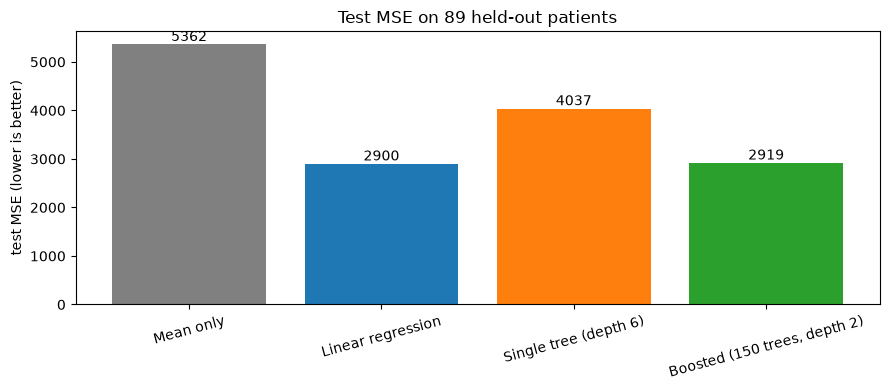

In [16]:
# ==== Hyperparameters (feel free to change!) ====
# No model is trained here: each model was fitted above with its own hyperparameter block.
# The setting below only controls how the comparison is displayed.
label_rotation = 15   # @param {type:"slider", min:0, max:90} rotation of the bar labels in degrees, try 0-45
# ================================================

# Collect all four models in a fixed order; read depth and rounds from the fitted models
# themselves, so the labels always describe the models actually being compared
names = ['Mean only', 'Linear regression',
         f'Single tree (depth {model_tree.max_depth})',
         f'Boosted ({len(model_boost.trees)} trees, depth {model_boost.max_depth})']
train_preds = [pred_mean_train, pred_linear_train, pred_tree_train, pred_boost_train]
test_preds = [pred_mean_test, pred_linear_test, pred_tree_test, pred_boost_test]
colors = ['gray', 'tab:blue', 'tab:orange', 'tab:green']

# Train and test MSE of each model (eq. 12)
train_mses = [mse(y_train, pred) for pred in train_preds]
test_mses = [mse(y_test, pred) for pred in test_preds]

# Print a small table
print(f"{'model':<32} | {'train MSE':>9} | {'test MSE':>9}")
print('-' * 56)
for name, tr, te in zip(names, train_mses, test_mses):
    print(f'{name:<32} | {tr:9.1f} | {te:9.1f}')

# Same test numbers as a bar chart, with the value written on top of each bar
plt.figure(figsize=(9, 4))
bars = plt.bar(range(len(names)), test_mses, color=colors)
for bar, value in zip(bars, test_mses):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.0f}', ha='center', va='bottom')
plt.xticks(range(len(names)), names, rotation=label_rotation)
plt.ylabel('test MSE (lower is better)')
plt.title(f'Test MSE on {len(y_test)} held-out patients')
plt.tight_layout()
plt.show()

The numbers are one thing. Let's also look at the predictions themselves. Each dot below is a test patient. A perfect model would put every dot on the dashed diagonal.

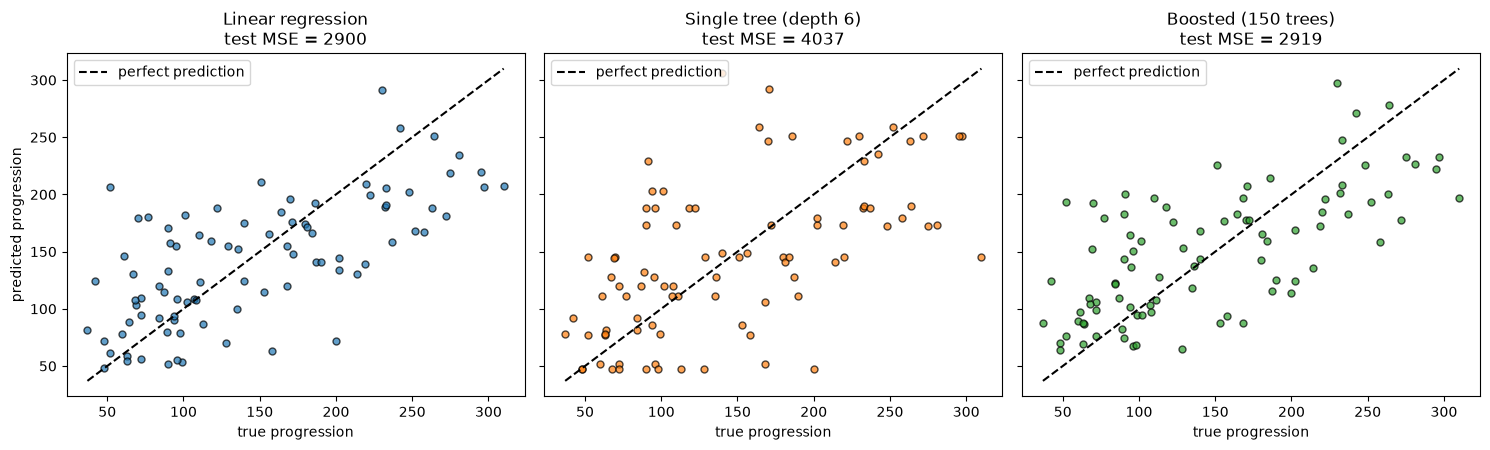

Linear regression         : 89 distinct predictions
Single tree (depth 6)     : 29 distinct predictions
Boosted (150 trees)       : 89 distinct predictions


In [17]:
# Predicted vs true for the three real models
panels = [('Linear regression', pred_linear_test, 'tab:blue'),
          (f'Single tree (depth {single_tree_depth})', pred_tree_test, 'tab:orange'),
          (f'Boosted ({n_rounds} trees)', pred_boost_test, 'tab:green')]

# Common range so the three panels are directly comparable
low = min(y_test.min(), *(pred.min() for _, pred, _ in panels))
high = max(y_test.max(), *(pred.max() for _, pred, _ in panels))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (name, pred, color) in zip(axes, panels):
    # One dot per test patient
    ax.scatter(y_test, pred, color=color, alpha=0.7, edgecolor='k', s=25)
    # The diagonal: prediction = truth
    ax.plot([low, high], [low, high], 'k--', label='perfect prediction')
    ax.set_title(f'{name}\ntest MSE = {mse(y_test, pred):.0f}')
    ax.set_xlabel('true progression')
    ax.legend(loc='upper left')
axes[0].set_ylabel('predicted progression')
plt.tight_layout()
plt.show()

# How many different values does each model actually predict on the test set?
for name, pred, _ in panels:
    print(f'{name:<26}: {len(np.unique(np.round(pred, 6)))} distinct predictions')

A few things to notice:

- **The single tree predicts in horizontal stripes.** Every patient in the same leaf gets the same number, so there are at most 64 distinct predictions. A leaf with only a few training patients outputs whatever those few happened to have.
- **The boosted model's predictions take many more values.** Each prediction is a sum of 150 small corrections, so the steps blur into something much smoother. Its cloud usually looks a lot like the linear regression one.
- **All three models tend to pull extreme patients toward the middle.** The 10 features do not carry enough information to pin down the very low and very high cases, so the safest bet is to stay closer to the average.

### The brakes on real data

On the six points, $\lambda$ and $\gamma$ changed numbers we could check by hand. Let's see what they do here. We train the boosted model with every combination of $\lambda \in \{0, 5\}$ and $\gamma \in \{0, 300\}$ and record the MSE after every round.

Why $\gamma = 300$, when $\gamma = 10$ was enough on the toy data? The gain in eq. 11 is measured in squared error summed over the patients in a node. Here the targets are in the hundreds and there are hundreds of patients, so gains easily reach the thousands. For $\gamma$ to have any effect, it must be on that scale. The same reasoning applies to $\lambda$. It acts like 5 extra phantom patients with residual 0 in every leaf, so it mostly affects small leaves.

For the test curves, we add one tree at a time and keep every intermediate prediction. Calling `predict(n_trees=k)` for every $k$ would redo the same work over and over. The train curves are already stored in `model.train_loss`. This cell trains up to three extra models, so give it 15-20 seconds.

setting                      | leaves/tree | final train | final test | best test round
------------------------------------------------------------------------------------------
lambda = 0, gamma = 0        |        3.87 |      1416.9 |     2919.4 | 41 (MSE 2711.5)
lambda = 5, gamma = 0        |        3.99 |      1613.3 |     2839.0 | 56 (MSE 2689.9)
lambda = 0, gamma = 300      |        3.80 |      1419.0 |     2898.1 | 41 (MSE 2711.5)
lambda = 5, gamma = 300      |        3.94 |      1608.1 |     2841.4 | 56 (MSE 2689.9)


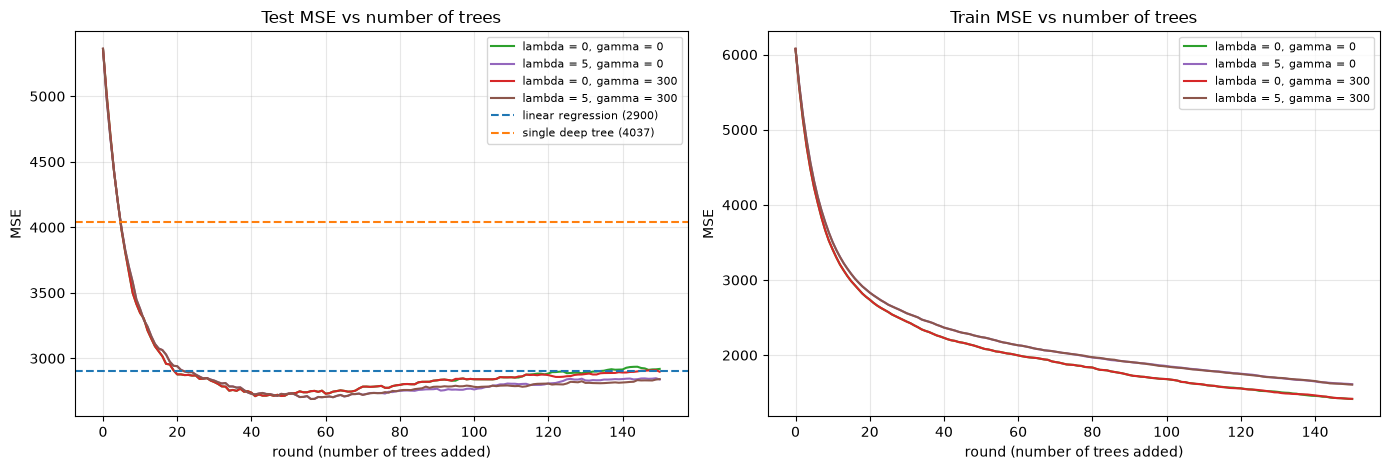

In [18]:
# ==== Hyperparameters (feel free to change!) ====
strong_lambda = 5.0    # @param {type:"number"} the 'on' value of lambda in the sweep (eq. 6), try 1-50
strong_gamma = 300.0   # @param {type:"number"} the 'on' value of gamma in the sweep (eq. 6), try 100-5000
# ================================================
# n_rounds, learning_rate and max_depth come from the boosting cell above, so all curves are comparable


def staged_mse(model, X, y):
    """MSE (eq. 12) after 0, 1, ..., M trees, adding one tree at a time (eq. 1)."""
    # Round 0: every prediction is the training mean
    y_pred = np.full(len(X), model.base_prediction)
    losses = [mse(y, y_pred)]
    for tree in model.trees:
        # Add the next shrunken tree on top of the running prediction (eq. 1)
        y_pred = y_pred + model.learning_rate * predict_tree_batch(tree, X)
        losses.append(mse(y, y_pred))
    return np.array(losses)


def count_leaves(node):
    """Number of leaves T of a tree, the quantity gamma charges for in eq. 6."""
    if node['leaf']:
        return 1
    return count_leaves(node['left']) + count_leaves(node['right'])


# Every combination of lambda in {0, strong} and gamma in {0, strong}
configs = [(0.0, 0.0), (strong_lambda, 0.0), (0.0, strong_gamma), (strong_lambda, strong_gamma)]
curve_colors = ['tab:green', 'tab:purple', 'tab:red', 'tab:brown']

sweep = []
for lam, gam in configs:
    # Reuse the model from above if it was trained with exactly these settings (saves a few seconds)
    same_settings = (model_boost.reg_lambda, model_boost.gamma, model_boost.learning_rate,
                     model_boost.max_depth, len(model_boost.trees)) == (lam, gam, learning_rate, max_depth, n_rounds)
    if same_settings:
        model = model_boost
    else:
        model = XGBoostRegressor(n_rounds, learning_rate, max_depth, lam, gam)
        model.fit(X_train, y_train)
    # Train MSE after each round (stored by fit) and test MSE after each round
    train_curve = np.array(model.train_loss)
    test_curve = staged_mse(model, X_test, y_test)
    # Average tree size: gamma should make trees smaller by refusing weak splits
    avg_leaves = np.mean([count_leaves(tree) for tree in model.trees])
    sweep.append((f'lambda = {lam:g}, gamma = {gam:g}', train_curve, test_curve, avg_leaves))

# Summary table. Note: picking the best round by looking at the test set is peeking (see below)
print(f"{'setting':<28} | {'leaves/tree':>11} | {'final train':>11} | {'final test':>10} | best test round")
print('-' * 90)
for label, train_curve, test_curve, avg_leaves in sweep:
    best_round = int(np.argmin(test_curve))
    print(f'{label:<28} | {avg_leaves:11.2f} | {train_curve[-1]:11.1f} | {test_curve[-1]:10.1f} | '
          f'{best_round} (MSE {test_curve[best_round]:.1f})')

# Reference lines: the two non-boosted contenders
mse_linear_test = mse(y_test, pred_linear_test)
mse_tree_test = mse(y_test, pred_tree_test)

# Plot test MSE (left) and train MSE (right) against the number of trees
rounds = np.arange(n_rounds + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (label, train_curve, test_curve, _), color in zip(sweep, curve_colors):
    axes[0].plot(rounds, test_curve, color=color, label=label)
    axes[1].plot(rounds, train_curve, color=color, label=label)
axes[0].axhline(mse_linear_test, color='tab:blue', linestyle='--', label=f'linear regression ({mse_linear_test:.0f})')
axes[0].axhline(mse_tree_test, color='tab:orange', linestyle='--', label=f'single deep tree ({mse_tree_test:.0f})')
axes[0].set_title('Test MSE vs number of trees')
axes[1].set_title('Train MSE vs number of trees')
for ax in axes:
    ax.set_xlabel('round (number of trees added)')
    ax.set_ylabel('MSE')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Reading the plots

- **Train side (right).** Here the brakes do exactly what the math says. With $\lambda$ on, every leaf weight is shrunk by $n_j/(n_j+\lambda)$, so each tree moves the predictions a bit less. With $\gamma$ on, weak splits are rejected, which you can see in the `leaves/tree` column. Either way, the train MSE falls more slowly.
- **Test side (left).** The test MSE drops quickly in the first few dozen rounds and then flattens. With these settings it may even creep back up a little. The differences between the four brake settings are much smaller than on the train side. With fewer than a hundred test patients, a difference of a hundred or so in MSE is well within noise, so don't over-read the order of the curves.
- **The best round is a peek.** We picked the best round by looking at the test set, which is cheating. In practice, you hold out a separate *validation* set and stop adding trees when its error stops improving. That is what XGBoost calls early stopping.
- **One deep tree vs many shallow ones.** The boosted curves usually end well below the single deep tree. Each shallow tree only makes a small, shrunken correction, and many slightly different corrections average out the noise that a single deep tree memorizes.
- **The honest part.** Linear regression is a tough opponent here, and it often matches or beats boosting on this dataset. The diabetes target looks close to a linear function of a few features plus a lot of noise. A sum of trees has to build each sloped trend out of many small steps, and every step costs a little variance.

So which model should we pick?

- **Trees and boosting** shine when the signal has thresholds, interactions ("only risky when both `bmi` and `bp` are high"), or other nonlinear shapes. They find these without any feature engineering, and they do not care about feature scaling.
- **Linear models** shine when the signal is close to linear, the data is small and noisy, or you need something fast and easy to explain. With one weight per feature, there is very little room to overfit.

A good habit: always fit the simple baseline first. It tells you whether the extra flexibility is buying anything.

## Experiment

Here are a few changes worth trying. After changing a value, re-run that cell and every cell below it.

1. **Learning rate vs rounds (Question 4, for real).**
   - In the boosting cell, set `learning_rate = 0.5`. In the sweep, the test curve should drop much faster, bottom out early, and then likely creep up while the train MSE keeps falling. Each tree is trusted too much.
   - Then try `learning_rate = 0.02`. After 150 rounds the curves are probably still falling, which means the model is underfitting. Raise `n_rounds` to see how many rounds it needs to catch up. Runtime grows linearly with `n_rounds`.
2. **Tree size.**
   - Set `max_depth = 1` (stumps). Each tree then looks at only one feature, so the model becomes a sum of step functions of single features and cannot represent interactions. How close does it get to linear regression?
   - Then try `max_depth = 4` and watch the gap between train and test MSE grow.
   - For the single tree, try `single_tree_depth = 2` or `3`. Does a shallow single tree beat the deep one? Check the smallest leaf size it prints.
3. **How much can we trust a small test set?** In the data cell, change `split_seed` (say to 0, 1, 2) and re-run everything. The order of linear regression and boosting may flip from seed to seed, while the single deep tree tends to stay behind. If a difference changes sign when you reshuffle the data, it is noise, not a real winner.

## Wrapping up

Today we built XGBoost from a mean, two derivatives, a parabola, and a greedy search. We checked every number on six points by hand, then let it loose on real patients. The main takeaways:

- **Boosting is gradient descent on the predictions.** Each new tree fits what the ensemble still gets wrong (eq. 3), and its leaf outputs are Newton steps (eq. 9).
- **Many small, shrunken trees beat one big tree.** No single tree gets to commit to the noise.
- **$\alpha$, $\lambda$, $\gamma$ and the tree depth are all brakes.** The train curves show them working clearly. On the test set, what matters is finding the right balance, not the strongest brake.
- **Boosting is not a universal winner.** When the signal is nearly linear and the data is noisy, a linear model is a strong and cheap competitor.

The real `xgboost` library runs this same algorithm with a lot of engineering on top:

- histogram-based split search instead of trying every threshold,
- built-in handling of missing values,
- row and column subsampling,
- early stopping on a validation set,
- parallel training.

None of that is magic either. It is the same objective (eq. 8), computed faster.

Thanks for following along, and see you in the next demo!